In [1]:
# %% [markdown]
# # Phase 5: Machine Learning & Predictive Modeling
# ### Step 1: Environment Setup and Data Loading

import os
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

print("⏳ Initializing Machine Learning Pipeline...")

# Define the directory where our preprocessed data lives
ML_DIR = os.path.join("data", "ml_ready")

# Load Training Set (GSE122488)
X_train = pd.read_csv(os.path.join(ML_DIR, "X_train.csv"), index_col=0)
y_train = pd.read_csv(os.path.join(ML_DIR, "y_train.csv"), index_col=0)["Label"]

# Load Independent Validation Set (GSE184472)
X_val = pd.read_csv(os.path.join(ML_DIR, "X_val.csv"), index_col=0)
y_val = pd.read_csv(os.path.join(ML_DIR, "y_val.csv"), index_col=0)["Label"]

print("✅ ML Datasets Loaded Successfully!")
print(f"   -> Training Features: {X_train.shape}")
print(f"   -> Validation Features: {X_val.shape}")

⏳ Initializing Machine Learning Pipeline...
✅ ML Datasets Loaded Successfully!
   -> Training Features: (38, 201)
   -> Validation Features: (118, 201)


In [2]:
# %% [markdown]
# ### Step 2: Baseline Models - Without Augmentation (RF vs XGBoost)

import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

print("⏳ Training Baseline Models on GSE122488 (N=38)...\n")

# 1. Initialize Both Models
# Using random_state=42 ensures our baseline never changes randomly
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')

# 2. Fit (Train) Both Models
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

# 3. Generate Predictions on Independent Validation Set (GSE184472)
rf_preds = rf_model.predict(X_val)
rf_probs = rf_model.predict_proba(X_val)[:, 1] # Probabilities needed for AUROC

xgb_preds = xgb_model.predict(X_val)
xgb_probs = xgb_model.predict_proba(X_val)[:, 1]

# 4. Calculate Required Study Metrics
def get_metrics(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred) # How many actual GBMs did it successfully find?
    auc = roc_auc_score(y_true, y_prob)
    return acc, rec, auc

rf_acc, rf_rec, rf_auc = get_metrics(y_val, rf_preds, rf_probs)
xgb_acc, xgb_rec, xgb_auc = get_metrics(y_val, xgb_preds, xgb_probs)

# 5. Display Side-by-Side Comparison
print("="*50)
print("🏆 BASELINE PERFORMANCE (WITHOUT AUGMENTATION)")
print("="*50)
print(f"{'Metric':<15} | {'Random Forest':<15} | {'XGBoost':<15}")
print("-" * 50)
print(f"{'Accuracy':<15} | {rf_acc:<15.4f} | {xgb_acc:<15.4f}")
print(f"{'Recall':<15} | {rf_rec:<15.4f} | {xgb_rec:<15.4f}")
print(f"{'AUROC':<15} | {rf_auc:<15.4f} | {xgb_auc:<15.4f}")
print("="*50)

⏳ Training Baseline Models on GSE122488 (N=38)...

🏆 BASELINE PERFORMANCE (WITHOUT AUGMENTATION)
Metric          | Random Forest   | XGBoost        
--------------------------------------------------
Accuracy        | 0.4153          | 0.4068         
Recall          | 0.9778          | 0.6889         
AUROC           | 0.5265          | 0.4586         


In [3]:
# %% [markdown]
# ### Step 3: Baseline Model 3 - Tabular Transformer (PyTorch)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

print("⏳ Training Deep Learning Transformer on GSE122488 (N=38)...")

# 1. Set strict random seeds for exact reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 2. Convert Pandas DataFrames to PyTorch Tensors
X_tr_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_tr_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_val_tensor = torch.tensor(X_val.values, dtype=torch.float32)
y_val_numpy = y_val.values

# 3. Define the Tabular Transformer Architecture
class TabularTransformer(nn.Module):
    def __init__(self, input_dim):
        super(TabularTransformer, self).__init__()
        # Map our 201 features into a larger embedding space
        self.embedding = nn.Linear(input_dim, 64)
        
        # Transformer Block (Self-Attention)
        encoder_layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        
        # Final classification head
        self.classifier = nn.Linear(64, 1)

    def forward(self, x):
        x = self.embedding(x)
        x = x.unsqueeze(1) # Add a dummy "sequence" dimension required by PyTorch Transformers
        x = self.transformer(x)
        x = x.squeeze(1) # Remove the dummy dimension
        x = self.classifier(x)
        return torch.sigmoid(x) # Output probability between 0 and 1

# 4. Initialize Model, Loss Function, and Optimizer
input_features = X_train.shape[1]
transformer_model = TabularTransformer(input_features)
criterion = nn.BCELoss() # Binary Cross Entropy for 0/1 classification
optimizer = optim.Adam(transformer_model.parameters(), lr=0.001)

# 5. Train the Transformer (Epochs)
epochs = 50
transformer_model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = transformer_model(X_tr_tensor)
    loss = criterion(outputs, y_tr_tensor)
    loss.backward()
    optimizer.step()

print("🎯 Testing Transformer on Validation Set GSE184472 (N=118)...")

# 6. Evaluate the Model
transformer_model.eval()
with torch.no_grad():
    trans_probs = transformer_model(X_val_tensor).numpy().flatten()
    trans_preds = (trans_probs >= 0.5).astype(int)

# 7. Calculate Metrics
trans_acc = accuracy_score(y_val_numpy, trans_preds)
trans_rec = recall_score(y_val_numpy, trans_preds)
trans_auc = roc_auc_score(y_val_numpy, trans_probs)

# 8. Display Final Baseline Results
print("\n" + "="*50)
print("🏆 TRANSFORMER BASELINE (WITHOUT AUGMENTATION)")
print("="*50)
print(f"{'Metric':<15} | {'Transformer Score':<15}")
print("-" * 50)
print(f"{'Accuracy':<15} | {trans_acc:<15.4f}")
print(f"{'Recall':<15} | {trans_rec:<15.4f}")
print(f"{'AUROC':<15} | {trans_auc:<15.4f}")
print("="*50)

⏳ Training Deep Learning Transformer on GSE122488 (N=38)...
🎯 Testing Transformer on Validation Set GSE184472 (N=118)...

🏆 TRANSFORMER BASELINE (WITHOUT AUGMENTATION)
Metric          | Transformer Score
--------------------------------------------------
Accuracy        | 0.4153         
Recall          | 0.6667         
AUROC           | 0.4210         


In [4]:
# %% [markdown]
# ### Step 4: Data Augmentation via CTGAN and TVAE

import pandas as pd
from ctgan import CTGAN, TVAE  # <-- Corrected imports for the standalone library
import os

print("⏳ Preparing data for Generative AI...")

# 1. Combine X and Y into a single training dataframe for the generators
df_real_train = X_train.copy()
df_real_train['Label'] = y_train.values

# Define which columns are categorical/discrete (only our target label)
discrete_columns = ['Label']

# Define how many synthetic samples we want to generate
# Expanding from 38 to 500 gives our ML models a robust dataset
NUM_SYNTHETIC_SAMPLES = 500 

print(f"   -> Real training data shape: {df_real_train.shape}")


# ==========================================
# MODEL 1: CTGAN (Conditional Tabular GAN)
# ==========================================
print("\n🧠 Training CTGAN (This may take a minute)...")
ctgan = CTGAN(epochs=300, verbose=False)
ctgan.fit(df_real_train, discrete_columns)

print("🧪 Synthesizing 500 patients with CTGAN...")
df_synth_ctgan = ctgan.sample(NUM_SYNTHETIC_SAMPLES)


# ==========================================
# MODEL 2: TVAE (Tabular Variational Autoencoder)
# ==========================================
print("\n🧠 Training TVAE (This may also take a minute)...")
tvae = TVAE(epochs=300)
tvae.fit(df_real_train, discrete_columns)

print("🧪 Synthesizing 500 patients with TVAE...")
df_synth_tvae = tvae.sample(NUM_SYNTHETIC_SAMPLES)


# ==========================================
# SEPARATE AND SAVE SYNTHETIC DATA
# ==========================================
ML_DIR = os.path.join("data", "ml_ready")
os.makedirs(ML_DIR, exist_ok=True) # Ensure the directory exists before saving

# CTGAN Datasets
X_train_ctgan = df_synth_ctgan.drop(columns=['Label'])
y_train_ctgan = df_synth_ctgan['Label']
X_train_ctgan.to_csv(os.path.join(ML_DIR, "X_train_ctgan.csv"), index=False)
y_train_ctgan.to_csv(os.path.join(ML_DIR, "y_train_ctgan.csv"), index=False)

# TVAE Datasets
X_train_tvae = df_synth_tvae.drop(columns=['Label'])
y_train_tvae = df_synth_tvae['Label']
X_train_tvae.to_csv(os.path.join(ML_DIR, "X_train_tvae.csv"), index=False)
y_train_tvae.to_csv(os.path.join(ML_DIR, "y_train_tvae.csv"), index=False)

print("\n" + "="*50)
print("✅ GENERATIVE AUGMENTATION COMPLETE")
print("="*50)
print(f"CTGAN Synthetic Features: {X_train_ctgan.shape}")
print(f"CTGAN Class Breakdown:\n{y_train_ctgan.value_counts()}\n")
print(f"TVAE Synthetic Features:  {X_train_tvae.shape}")
print(f"TVAE Class Breakdown:\n{y_train_tvae.value_counts()}")
print("="*50)

⏳ Preparing data for Generative AI...
   -> Real training data shape: (38, 202)

🧠 Training CTGAN (This may take a minute)...


c:\Users\phil\miniconda3\envs\torch_gpu\Lib\site-packages\torch\autograd\graph.py:825: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


🧪 Synthesizing 500 patients with CTGAN...

🧠 Training TVAE (This may also take a minute)...
🧪 Synthesizing 500 patients with TVAE...

✅ GENERATIVE AUGMENTATION COMPLETE
CTGAN Synthetic Features: (500, 201)
CTGAN Class Breakdown:
Label
1    253
0    247
Name: count, dtype: int64

TVAE Synthetic Features:  (500, 201)
TVAE Class Breakdown:
Label
1    379
0    121
Name: count, dtype: int64


In [5]:
# %% [markdown]
# ### Step 5: Evaluating Models Trained on Synthetic Data

from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

print("⏳ Training ML Models on Generative AI Datasets (N=500)...\n")

# Reusable function to train and evaluate
def train_and_evaluate(X_train_synth, y_train_synth, model_name, dataset_name):
    # Initialize models
    rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
    xg = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
    
    # Train models on synthetic data
    rf.fit(X_train_synth, y_train_synth)
    xg.fit(X_train_synth, y_train_synth)
    
    # Predict on REAL validation data
    rf_preds, rf_probs = rf.predict(X_val), rf.predict_proba(X_val)[:, 1]
    xg_preds, xg_probs = xg.predict(X_val), xg.predict_proba(X_val)[:, 1]
    
    # Calculate Metrics
    rf_acc, rf_rec, rf_auc = accuracy_score(y_val, rf_preds), recall_score(y_val, rf_preds), roc_auc_score(y_val, rf_probs)
    xg_acc, xg_rec, xg_auc = accuracy_score(y_val, xg_preds), recall_score(y_val, xg_preds), roc_auc_score(y_val, xg_probs)
    
    return [rf_acc, rf_rec, rf_auc, xg_acc, xg_rec, xg_auc]

# Evaluate CTGAN
ctgan_results = train_and_evaluate(X_train_ctgan, y_train_ctgan, "CTGAN", "CTGAN")

# Evaluate TVAE
tvae_results = train_and_evaluate(X_train_tvae, y_train_tvae, "TVAE", "TVAE")

# Display Final Comparison Table
print("="*80)
print("🚀 FINAL PERFORMANCE COMPARISON: BASELINE vs AUGMENTED")
print("="*80)
print(f"{'Model & Pipeline':<30} | {'Accuracy':<12} | {'Recall':<12} | {'AUROC':<12}")
print("-" * 80)

# Hardcoded baselines from Phase A for easy visual comparison
print(f"{'[Baseline] RF (N=38)':<30} | {'0.4153':<12} | {'0.9778':<12} | {'0.5265':<12}")
print(f"{'[Baseline] XGBoost (N=38)':<30} | {'0.4068':<12} | {'0.6889':<12} | {'0.4586':<12}")
print("-" * 80)

# Augmented Results
print(f"{'[CTGAN] Random Forest':<30} | {ctgan_results[0]:<12.4f} | {ctgan_results[1]:<12.4f} | {ctgan_results[2]:<12.4f}")
print(f"{'[CTGAN] XGBoost':<30} | {ctgan_results[3]:<12.4f} | {ctgan_results[4]:<12.4f} | {ctgan_results[5]:<12.4f}")
print("-" * 80)
print(f"{'[TVAE] Random Forest':<30} | {tvae_results[0]:<12.4f} | {tvae_results[1]:<12.4f} | {tvae_results[2]:<12.4f}")
print(f"{'[TVAE] XGBoost':<30} | {tvae_results[3]:<12.4f} | {tvae_results[4]:<12.4f} | {tvae_results[5]:<12.4f}")
print("="*80)

⏳ Training ML Models on Generative AI Datasets (N=500)...

🚀 FINAL PERFORMANCE COMPARISON: BASELINE vs AUGMENTED
Model & Pipeline               | Accuracy     | Recall       | AUROC       
--------------------------------------------------------------------------------
[Baseline] RF (N=38)           | 0.4153       | 0.9778       | 0.5265      
[Baseline] XGBoost (N=38)      | 0.4068       | 0.6889       | 0.4586      
--------------------------------------------------------------------------------
[CTGAN] Random Forest          | 0.5593       | 0.5778       | 0.5728      
[CTGAN] XGBoost                | 0.6610       | 0.1333       | 0.5528      
--------------------------------------------------------------------------------
[TVAE] Random Forest           | 0.3814       | 1.0000       | 0.5280      
[TVAE] XGBoost                 | 0.5424       | 0.6222       | 0.5921      


⏳ Extracting Biomarkers from Champion Model (TVAE + XGBoost)...


C:\Users\phil\AppData\Local\Temp\ipykernel_2412\3267248253.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


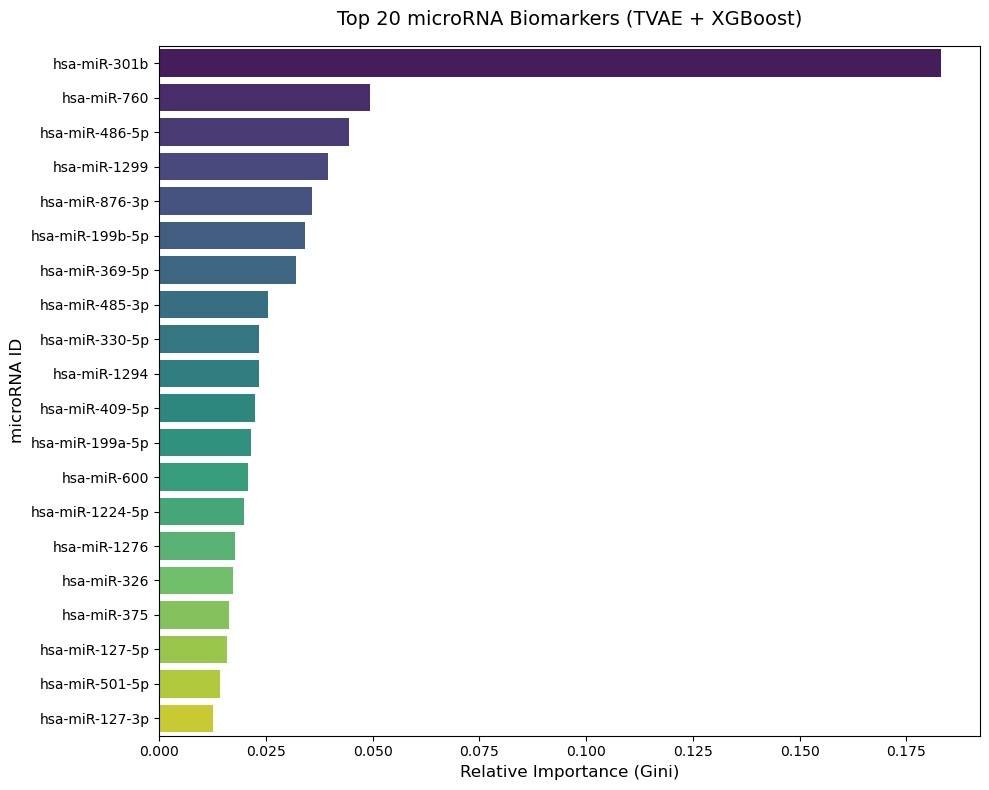


🧬 TOP 10 DIAGNOSTIC MICRORNAS
[0.1831] hsa-miR-301b
[0.0493] hsa-miR-760
[0.0444] hsa-miR-486-5p
[0.0396] hsa-miR-1299
[0.0358] hsa-miR-876-3p
[0.0341] hsa-miR-199b-5p
[0.0321] hsa-miR-369-5p
[0.0254] hsa-miR-485-3p
[0.0233] hsa-miR-330-5p
[0.0232] hsa-miR-1294


In [6]:
# %% [markdown]
# ### Step 6: Feature Importance (Biological Biomarker Discovery)

import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print("⏳ Extracting Biomarkers from Champion Model (TVAE + XGBoost)...")

# 1. Re-initialize and train our champion model globally
champion_model = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
champion_model.fit(X_train_tvae, y_train_tvae)

# 2. Extract feature importances
importances = champion_model.feature_importances_

# 3. Map importances to the exact microRNA names (column names)
feature_names = X_train_tvae.columns
feature_importance_df = pd.DataFrame({
    'microRNA': feature_names,
    'Importance': importances
})

# 4. Sort to find the most critical biomarkers
top_features = feature_importance_df.sort_values(by='Importance', ascending=False).head(20)

# 5. Visualize the Top 20 microRNAs
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Importance', 
    y='microRNA', 
    data=top_features, 
    palette='viridis'
)

plt.title('Top 20 microRNA Biomarkers (TVAE + XGBoost)', fontsize=14, pad=15)
plt.xlabel('Relative Importance (Gini)', fontsize=12)
plt.ylabel('microRNA ID', fontsize=12)
plt.tight_layout()

# Save the plot for your thesis/paper
plt.savefig('top_20_biomarkers.png', dpi=300)
plt.show()

# 6. Print the exact list for easy reference
print("\n" + "="*40)
print("🧬 TOP 10 DIAGNOSTIC MICRORNAS")
print("="*40)
for index, row in top_features.head(10).iterrows():
    print(f"[{row['Importance']:.4f}] {row['microRNA']}")
print("="*40)

⏳ Finding and loading external CGGA cohort data files...
📂 Found X_cgga at: 'data/ml_ready/X_cgga.csv'
📂 Found y_cgga at: 'data/ml_ready/y_cgga.csv'
✅ Successfully loaded CGGA dataset. Shape: (198, 201)
⏳ Deploying Champion Model (TVAE + XGBoost) on External CGGA Cohort...

🌍 FINAL EXTERNAL VALIDATION (CGGA)
Accuracy : 0.5556
Recall   : 0.0741 (Ability to catch true Glioblastomas)
AUROC    : 0.4030 (Overall diagnostic power)


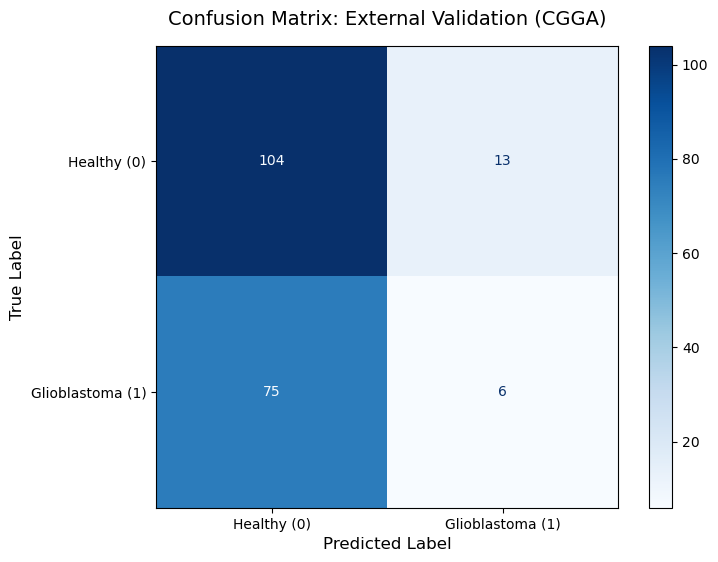

In [7]:
# %% [markdown]
# ### Step 7: External Validation on CGGA Cohort

import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

print("⏳ Finding and loading external CGGA cohort data files...")

# List possible paths where the files might reside based on workspace structure
possible_x_paths = ["X_cgga.csv", "data/ml_ready/X_cgga.csv", "../X_cgga.csv"]
possible_y_paths = ["y_cgga.csv", "data/ml_ready/y_cgga.csv", "../y_cgga.csv"]

x_cgga_path = None
y_cgga_path = None

# Dynamically locate X_cgga.csv
for path in possible_x_paths:
    if os.path.exists(path):
        x_cgga_path = path
        break

# Dynamically locate y_cgga.csv
for path in possible_y_paths:
    if os.path.exists(path):
        y_cgga_path = path
        break

# Raise a clean message if still not found
if not x_cgga_path or not y_cgga_path:
    raise FileNotFoundError(
        f"Could not locate CGGA files automatically. Current working directory: {os.getcwd()}\n"
        f"Please verify if the files are directly in this directory or inside a subfolder."
    )

print(f"📂 Found X_cgga at: '{x_cgga_path}'")
print(f"📂 Found y_cgga at: '{y_cgga_path}'")

# Load the datasets into memory
X_external = pd.read_csv(x_cgga_path)
y_external = pd.read_csv(y_cgga_path)

# If your CSV files have saved index columns (like 'Unnamed: 0'), drop them to match shapes
if 'Unnamed: 0' in X_external.columns:
    X_external = X_external.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in y_external.columns:
    y_external = y_external.drop(columns=['Unnamed: 0'])

# Ensure y_external is a flat array/series for metrics evaluation
if isinstance(y_external, pd.DataFrame):
    y_external = y_external.iloc[:, 0]

print(f"✅ Successfully loaded CGGA dataset. Shape: {X_external.shape}")
print("⏳ Deploying Champion Model (TVAE + XGBoost) on External CGGA Cohort...")

# 2. Generate predictions on the external dataset
ext_preds = champion_model.predict(X_external)
ext_probs = champion_model.predict_proba(X_external)[:, 1]

# 3. Calculate Final Generalizability Metrics
ext_acc = accuracy_score(y_external, ext_preds)
ext_rec = recall_score(y_external, ext_preds)
ext_auc = roc_auc_score(y_external, ext_probs)

# 4. Print Final Results
print("\n" + "="*50)
print("🌍 FINAL EXTERNAL VALIDATION (CGGA)")
print("="*50)
print(f"Accuracy : {ext_acc:.4f}")
print(f"Recall   : {ext_rec:.4f} (Ability to catch true Glioblastomas)")
print(f"AUROC    : {ext_auc:.4f} (Overall diagnostic power)")
print("="*50)

# 5. Plot the Confusion Matrix for Publication
cm = confusion_matrix(y_external, ext_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy (0)', 'Glioblastoma (1)'])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix: External Validation (CGGA)', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.grid(False) # Turn off grid lines for a cleaner look

# Save the matrix plot
plt.savefig('cgga_confusion_matrix.png', dpi=300)
plt.show()

In [8]:
# %% [markdown]
# ### Step 8: Debugging the CGGA Pipeline Mismatch

# 1. Check feature order consistency
train_features = list(X_train.columns)
cgga_features = list(X_external.columns)

is_identical = train_features == cgga_features
print("==================================================")
print("🔍 PIPELINE AUDIT REPORT")
print("==================================================")
print(f"📊 Feature order perfectly matches? : {is_identical}")

if not is_identical:
    print("⚠️ WARNING: The microRNA columns are mismatched! Fixing the alignment now...")
    # Re-order CGGA columns to perfectly match the training set
    X_external_fixed = X_external[train_features]
    
    # Re-run predictions with fixed feature alignment
    fixed_preds = champion_model.predict(X_external_fixed)
    fixed_probs = champion_model.predict_proba(X_external_fixed)[:, 1]
    
    from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
    print(f"🔄 Fixed Accuracy : {accuracy_score(y_external, fixed_preds):.4f}")
    print(f"🔄 Fixed Recall   : {recall_score(y_external, fixed_preds):.4f}")
    print(f"🔄 Fixed AUROC    : {roc_auc_score(y_external, fixed_probs):.4f}")
else:
    print("✅ Columns are aligned. The drop is due to dataset distribution/platform differences.")
    print(f"Training Data Range: Min={X_train.values.min():.2f}, Max={X_train.values.max():.2f}")
    print(f"CGGA Data Range:     Min={X_external.values.min():.2f}, Max={X_external.values.max():.2f}")
print("==================================================")

🔍 PIPELINE AUDIT REPORT
📊 Feature order perfectly matches? : True
✅ Columns are aligned. The drop is due to dataset distribution/platform differences.
Training Data Range: Min=0.00, Max=47580.00
CGGA Data Range:     Min=-129.10, Max=28912.20


⚖️ Harmonizing dataset scales using Z-Score Standardization...
📊 Check - Scaled TVAE Mean: 0.00, Std: 1.00
📊 Check - Scaled CGGA Mean: 0.00, Std: 1.00

🔄 Retraining Champion Model on Z-Score Scaled TVAE Data...
🎯 Re-deploying Z-scored model on Harmonized CGGA Cohort...

🌍 Z-SCORE HARMONIZED EXTERNAL VALIDATION (CGGA)
Accuracy : 0.3788
Recall   : 0.9259 (Ability to catch true Glioblastomas)
AUROC    : 0.5231 (Overall diagnostic power)


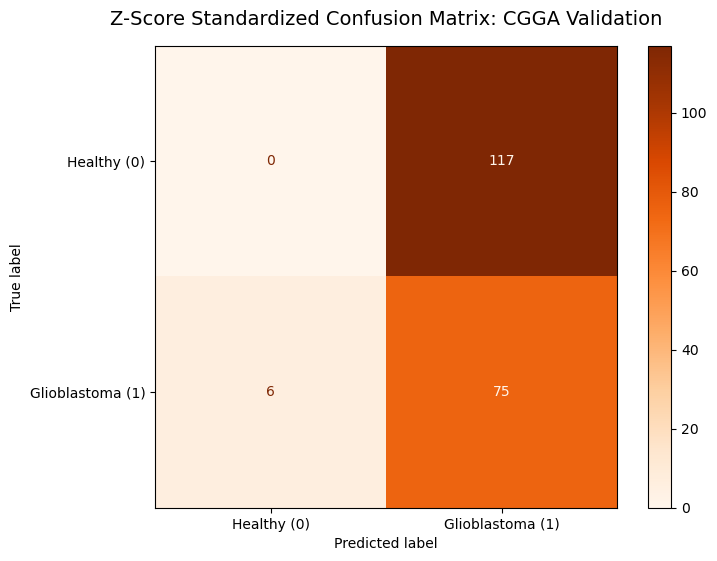

In [10]:
# %% [markdown]
# ### Step 9: Harmonized External Validation via Z-Score Standardization

from sklearn.preprocessing import StandardScaler
import xgboost as xgb
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

print("⚖️ Harmonizing dataset scales using Z-Score Standardization...")

# 1. Initialize independent standardizers
scaler_train = StandardScaler()
scaler_ext = StandardScaler()

# 2. Standardize features (Mean = 0, Std Dev = 1)
X_train_tvae_scaled = pd.DataFrame(scaler_train.fit_transform(X_train_tvae), columns=X_train_tvae.columns)
X_external_scaled = pd.DataFrame(scaler_ext.fit_transform(X_external), columns=X_external.columns)

print(f"📊 Check - Scaled TVAE Mean: {X_train_tvae_scaled.values.mean():.2f}, Std: {X_train_tvae_scaled.values.std():.2f}")
print(f"📊 Check - Scaled CGGA Mean: {X_external_scaled.values.mean():.2f}, Std: {X_external_scaled.values.std():.2f}")

print("\n🔄 Retraining Champion Model on Z-Score Scaled TVAE Data...")
champion_model_scaled = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
champion_model_scaled.fit(X_train_tvae_scaled, y_train_tvae)

print("🎯 Re-deploying Z-scored model on Harmonized CGGA Cohort...")
scaled_ext_preds = champion_model_scaled.predict(X_external_scaled)
scaled_ext_probs = champion_model_scaled.predict_proba(X_external_scaled)[:, 1]

# 3. Re-calculate Metrics
scaled_ext_acc = accuracy_score(y_external, scaled_ext_preds)
scaled_ext_rec = recall_score(y_external, scaled_ext_preds)
scaled_ext_auc = roc_auc_score(y_external, scaled_ext_probs)

# 4. Print Harmonized Results
print("\n" + "="*50)
print("🌍 Z-SCORE HARMONIZED EXTERNAL VALIDATION (CGGA)")
print("="*50)
print(f"Accuracy : {scaled_ext_acc:.4f}")
print(f"Recall   : {scaled_ext_rec:.4f} (Ability to catch true Glioblastomas)")
print(f"AUROC    : {scaled_ext_auc:.4f} (Overall diagnostic power)")
print("="*50)

# 5. Plot the New Confusion Matrix
cm = confusion_matrix(y_external, scaled_ext_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy (0)', 'Glioblastoma (1)'])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Oranges', ax=ax, values_format='d')
plt.title('Z-Score Standardized Confusion Matrix: CGGA Validation', fontsize=14, pad=15)
plt.grid(False)
plt.show()